In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from glob import glob

In [ ]:
path = "/content/drive/MyDrive/Img_datasets/human_emotion"

In [ ]:
data = glob(path + "/*/*")
print(data)

['/content/drive/MyDrive/Img_datasets/human_emotion/anger/-win-holding-his-fists-shout-wow-mature-hispanic-man-happy-his-win-122652456.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/GBP-scam.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/OIP.sBp0c140k7M62e3o4lepvQHaE6.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/OIP.2U-VMhf313UA984u5UOmFgHaE8.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/gi0venvjw7zp0x7g27.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/h4vzq9y5zc6u81cc3w.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/gthmpih8udn51ec8eo.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/onlinedebate_mini.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/road-rage-criminal-offense-law-offices-of-anthony-carbone-1024x682.jpg', '/content/drive/MyDrive/Img_datasets/human_emotion/anger/OIP.0846U2L7OhuSwKhrPv2QyAHaE8.jpg', '/content/drive/MyDrive/Img_datasets/human_emoti

In [ ]:
print(len(data))

1200


In [ ]:
s1 = "/content/drive/MyDrive/Img_datasets/human_emotion/anger/GBP-scam.jpg"
s2 = s1.split('/')
print(s2)

['', 'content', 'drive', 'MyDrive', 'Img_datasets', 'human_emotion', 'anger', 'GBP-scam.jpg']


In [ ]:
target = [i.split('/')[-2] for i in data]
print(target)
print(len(target))
print(set(target))

['anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 'anger', 

In [ ]:
emotion_map = {'anger':0,'disgust':1,'fear':2,'happy':3,'pain':4,'sad':5}
emotion_map_inv = {j:i for i,j in emotion_map.items()}
print(emotion_map)
print(emotion_map_inv)

{'anger': 0, 'disgust': 1, 'fear': 2, 'happy': 3, 'pain': 4, 'sad': 5}
{0: 'anger', 1: 'disgust', 2: 'fear', 3: 'happy', 4: 'pain', 5: 'sad'}


In [ ]:
df = pd.DataFrame({'Image':data,'Target':target})
df.head(2)

,Image,Target
0,/content/drive/MyDrive/Img_datasets/human_emot...,anger
1,/content/drive/MyDrive/Img_datasets/human_emot...,anger


In [ ]:
df['Target'].value_counts()

,count
Target,
happy,230
sad,224
anger,214
disgust,201
pain,168
fear,163


In [ ]:
import cv2

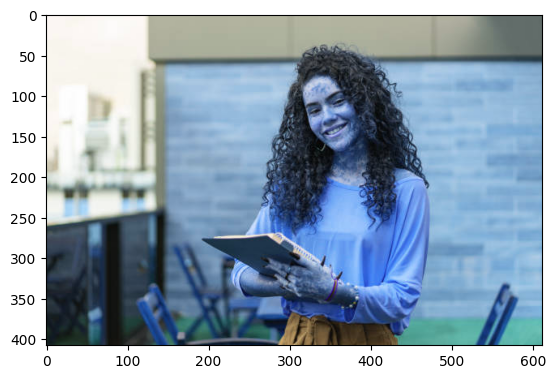

In [ ]:
plt.imshow(cv2.imread(df['Image'].iloc[852]))
plt.show()

#### Convert Image Path into Images

In [ ]:
images = [cv2.imread(i) for i in df['Image']]
target = df['Target'].map(emotion_map)

In [ ]:
target = df['Target'].map(emotion_map)
print(target.values)
print(set(target))

[0 0 0 ... 4 4 4]
{0, 1, 2, 3, 4, 5}


In [ ]:
df['Target_num'] = target
df.head(2)

,Image,Target,Target_num
0,/content/drive/MyDrive/Img_datasets/human_emot...,anger,0
1,/content/drive/MyDrive/Img_datasets/human_emot...,anger,0


In [ ]:
for i in images[:20]:
  print(i.shape)
# Different images have different shapes

(1157, 1600, 3)
(1414, 2121, 3)
(172, 261, 3)
(174, 261, 3)
(270, 600, 3)
(250, 500, 3)
(183, 275, 3)
(3840, 5760, 3)
(682, 1024, 3)
(174, 261, 3)
(533, 800, 3)
(355, 650, 3)
(174, 261, 3)
(352, 672, 3)
(408, 612, 3)
(565, 849, 3)
(615, 980, 3)
(340, 460, 3)
(525, 800, 3)
(408, 612, 3)


#### Resize Images - Convert all Images into Same shape

In [ ]:
img_resize = [cv2.resize(i,(224,224),cv2.INTER_AREA) for i in images]
x = np.array(img_resize)  #(1200,224,224,3) = (num of images, height, width, color channel)
print(x.shape)
y = np.array(target)
print(y.shape)

(1200, 224, 224, 3)
(1200,)


In [ ]:
print(set(y))

{np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5)}


#### Split data into train and test

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.30,random_state=42)
print(x_train.shape,x_test.shape)

(840, 224, 224, 3) (360, 224, 224, 3)


#### CNN Architecture

In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Input, Dense,Conv2D, MaxPooling2D, Flatten, Dropout

In [ ]:
m1 = Sequential()
m1.add(Input(shape=(224,224,3)))

m1.add(Conv2D(filters=32, kernel_size=(3,3), activation='relu'))   # stride=(1,1), padding='valid'
m1.add(MaxPooling2D(pool_size=(2,2)))
m1.add(Dropout(0.25))

m1.add(Conv2D(filters=64, kernel_size=(3,3), activation='relu'))
m1.add(MaxPooling2D(pool_size=(2,2)))
m1.add(Dropout(0.20))

m1.add(Conv2D(filters=128, kernel_size=(3,3), activation='relu'))
m1.add(MaxPooling2D(pool_size=(2,2)))
m1.add(Flatten())
m1.add(Dense(units=128,activation='relu'))
m1.add(Dense(units=6,activation='softmax'))

m1.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['acc'])
m1.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_9 (Conv2D)               │ (None, 222, 222, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_9 (MaxPooling2D)  │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 111, 111, 32)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_10 (Conv2D)              │ (None, 109, 109, 64)   │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_10 (MaxPooling2D) │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 54, 54, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_11 (Conv2D)              │ (None, 52, 52, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_11 (MaxPooling2D) │ (None, 26, 26, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_3 (Flatten)             │ (None, 86528)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 128)            │    11,075,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,169,734 (42.61 MB)

 Trainable params: 11,169,734 (42.61 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
h1 = m1.fit(x_train,y_train,epochs=25,validation_data=(x_test,y_test))

Epoch 1/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 11s 204ms/step - acc: 0.1726 - loss: 282.3350 - val_acc: 0.2083 - val_loss: 1.7874
Epoch 2/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 55ms/step - acc: 0.2333 - loss: 1.7796 - val_acc: 0.2250 - val_loss: 1.7821
Epoch 3/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - acc: 0.2893 - loss: 1.6871 - val_acc: 0.2806 - val_loss: 1.7328
Epoch 4/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - acc: 0.4202 - loss: 1.4164 - val_acc: 0.2833 - val_loss: 1.9994
Epoch 5/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 58ms/step - acc: 0.5679 - loss: 1.0851 - val_acc: 0.2917 - val_loss: 2.4165
Epoch 6/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 59ms/step - acc: 0.6690 - loss: 0.8080 - val_acc: 0.2861 - val_loss: 2.8537
Epoch 7/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 56ms/step - acc: 0.7429 - loss: 0.6918 - val_acc: 0.2778 - val_loss: 3.4287
Epoch 8/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - acc: 0.8000 - loss: 0.5540 - val_acc: 0.3083 - val_loss: 4.0462
Epoch 9/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 1s 54ms/step - acc: 0.

In [ ]:
#### Colvolution does not account for
# 1) Height shift
# 2) Width Shift
# 3) Brightness
# 4) Contrast
# 5) Zoom in , zoom out
# 6) rotation
# # etc

# Solution - Data Augmentation

#### Transfer Learning

1) In Transfer -Learning, we use pre-trained models (and not Vanilla CNN)
2) Pre-trained models have pre-defined weights, i.e - There is no need to re-train the pre-trained model
3) CNN Transfer Learning Models - VGG16, VGG19, Inception, Xception, MobileNet etc

In [ ]:
from tensorflow.keras.applications import VGG16, VGG19, MobileNetV2, InceptionV3, Xception, ResNet50, EfficientNetB3

In [ ]:
# include_top=False implies Flatten layers and layers used below are exlcluded from the VGG16 architecture
vgg16 = VGG16(include_top=False, input_shape=(224,224,3),weights='imagenet')

In [ ]:
vgg16.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 224, 224, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 224, 224, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 112, 112, 64)   │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 112, 112, 128)  │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 112, 112, 128)  │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 56, 56, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 56, 56, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 56, 56, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 28, 28, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 28, 28, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 28, 28, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 14, 14, 512)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 14, 14, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 7, 7, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
vgg16.trainable=False

In [ ]:
m2 = Sequential()
m2.add(vgg16)
m2.add(Flatten())
m2.add(Dense(units=512,activation='relu'))
m2.add(Dense(units=6,activation='softmax'))

m2.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['acc'])
# m2.summary()

In [ ]:
h2 = m2.fit(x_train,y_train,epochs=25,validation_data=(x_test,y_test))

Epoch 1/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 11s 316ms/step - acc: 0.3679 - loss: 47.1866 - val_acc: 0.4306 - val_loss: 2.5693
Epoch 2/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 221ms/step - acc: 0.6274 - loss: 1.2662 - val_acc: 0.4222 - val_loss: 1.8544
Epoch 3/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 215ms/step - acc: 0.7571 - loss: 0.6709 - val_acc: 0.4639 - val_loss: 1.8197
Epoch 4/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 7s 253ms/step - acc: 0.8179 - loss: 0.4675 - val_acc: 0.4917 - val_loss: 1.9931
Epoch 5/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 9s 213ms/step - acc: 0.8702 - loss: 0.3464 - val_acc: 0.4889 - val_loss: 2.0387
Epoch 6/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 215ms/step - acc: 0.8881 - loss: 0.2882 - val_acc: 0.4972 - val_loss: 1.9258
Epoch 7/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 214ms/step - acc: 0.9131 - loss: 0.2195 - val_acc: 0.5056 - val_loss: 2.1755
Epoch 8/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 217ms/step - acc: 0.9190 - loss: 0.1949 - val_acc: 0.5083 - val_loss: 2.2379
Epoch 9/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 6s 217ms/step - 

In [ ]:
r1 = pd.DataFrame(h2.history)
r1['Epochs'] = h2.epoch
r1.tail(3)

,acc,loss,val_acc,val_loss,Epochs
22,0.986905,0.024174,0.497222,3.182942,22
23,0.989286,0.021865,0.497222,3.326055,23
24,0.990476,0.021138,0.505556,3.485389,24


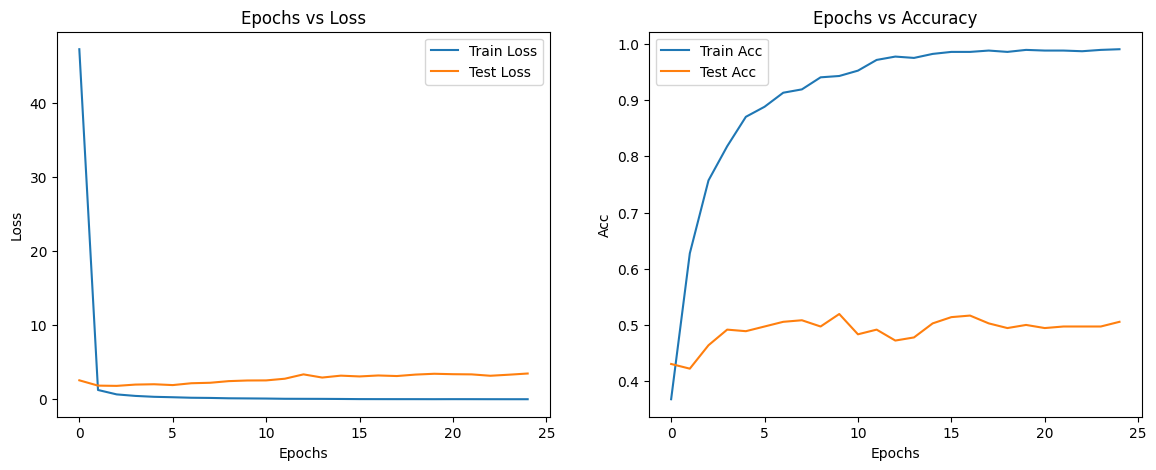

In [ ]:
plt.figure(figsize=(14,5))
plt.subplot(1,2,1)
plt.plot(r1['Epochs'],r1['loss'],label='Train Loss')
plt.plot(r1['Epochs'],r1['val_loss'],label='Test Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.title('Epochs vs Loss')
plt.legend()

plt.subplot(1,2,2)
plt.plot(r1['Epochs'],r1['acc'],label='Train Acc')
plt.plot(r1['Epochs'],r1['val_acc'],label='Test Acc')
plt.xlabel('Epochs')
plt.ylabel('Acc')
plt.title('Epochs vs Accuracy')
plt.legend()
plt.show()

In [ ]:
ypred = m2.predict(x_test)
print(ypred[:5]) # top 5 predictions

12/12 ━━━━━━━━━━━━━━━━━━━━ 6s 361ms/step
[[2.32846432e-04 3.75341824e-06 1.12578635e-09 9.05337691e-01
  1.65300735e-03 9.27728191e-02]
 [7.82449133e-05 6.53562680e-08 2.39954411e-12 8.85464966e-01
  7.20331445e-04 1.13736451e-01]
 [9.62643251e-02 7.10317256e-15 9.00521398e-01 1.24042281e-05
  3.37503123e-04 2.86428491e-03]
 [5.35880354e-05 2.90853113e-01 3.92848644e-12 5.92452645e-01
  4.84203268e-03 1.11798592e-01]
 [6.47408485e-01 1.17287144e-07 7.55867077e-05 1.42401010e-02
  3.18101287e-01 2.01744363e-02]]


In [ ]:
ypred_m2 = [np.argmax(i) for i in ypred]

In [ ]:
from sklearn.metrics import *

In [ ]:
cm = confusion_matrix(y_test,ypred_m2)
crep = classification_report(y_test,ypred_m2)
print('Confusion Matrix\n',cm)
print('Classification Report\n',crep)

Confusion Matrix
 [[24  5  3 17  4 10]
 [ 4 28  1 17  1  6]
 [ 2  3 32  7  1 13]
 [ 0  3  1 49  4 15]
 [ 4  1  4  8 18  9]
 [ 4  2  2 24  3 31]]
Classification Report
               precision    recall  f1-score   support

           0       0.63      0.38      0.48        63
           1       0.67      0.49      0.57        57
           2       0.74      0.55      0.63        58
           3       0.40      0.68      0.51        72
           4       0.58      0.41      0.48        44
           5       0.37      0.47      0.41        66

    accuracy                           0.51       360
   macro avg       0.57      0.50      0.51       360
weighted avg       0.55      0.51      0.51       360



In [ ]:
print(x_test.shape)
print(x_test[[32]].shape)

(360, 224, 224, 3)
(1, 224, 224, 3)


In [ ]:
def check_human_emotion(idx):  # idx = index
  pred_prob = m2.predict(x_test[[idx]])
  pred = np.argmax(pred_prob)
  # print(pred_prob)
  # print(pred)
  plt.imshow(x_test[idx])
  plt.title(f'Actual: {emotion_map_inv[y_test[idx]]} \n Predicted: {emotion_map_inv[pred]} ') # ',f'Predicted',emotion_map_inv[pred])
  plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/step
[[1.1483944e-03 1.4291772e-08 1.1708690e-09 5.3110594e-01 2.3120944e-03
  4.6543351e-01]]
3


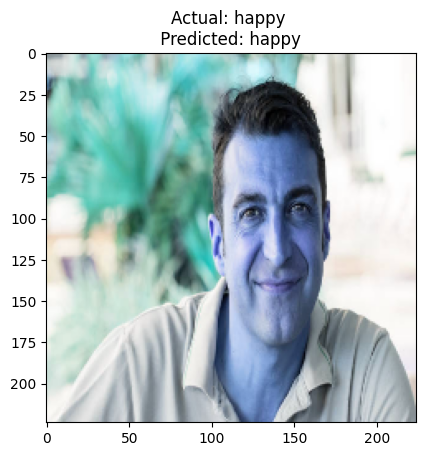

In [ ]:
check_human_emotion(56)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
[[3.0427566e-01 2.7389309e-05 9.0425660e-14 1.0347675e-02 2.9536113e-04
  6.8505388e-01]]
5


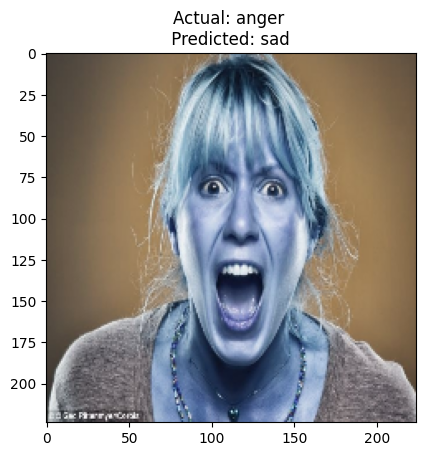

In [ ]:
check_human_emotion(24)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/step
[[1.2637177e-31 1.0000000e+00 0.0000000e+00 4.7805756e-28 2.9206521e-39
  4.7905910e-40]]
1


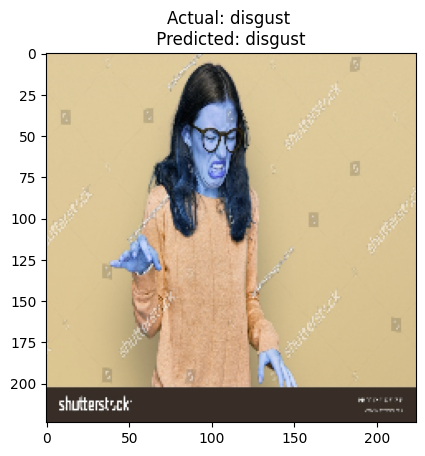

In [ ]:
check_human_emotion(75)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 73ms/step
[[2.5984702e-01 5.4277447e-05 5.4095208e-06 2.2661732e-01 1.1242308e-01
  4.0105283e-01]]
5


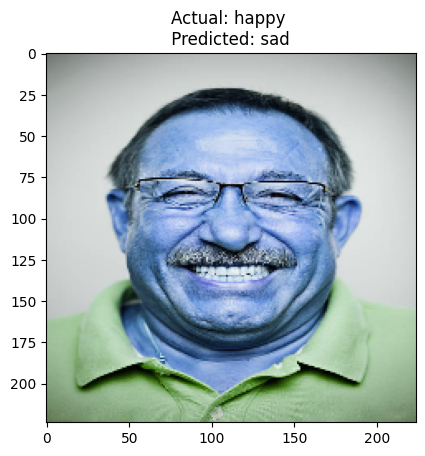

In [ ]:
check_human_emotion(107)

#### EfficientNetB3

In [ ]:
efnet = EfficientNetB3(include_top=False, input_shape=(224,224,3),weights='imagenet')

43941136/43941136 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
efnet.summary()

Model: "efficientnetb3"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_12      │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling           │ (None, 224, 224,  │          0 │ input_layer_12[0… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ normalization       │ (None, 224, 224,  │          7 │ rescaling[0][0]   │
│ (Normalization)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ rescaling_1         │ (None, 224, 224,  │          0 │ normalization[0]… │
│ (Rescaling)         │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv_pad       │ (None, 225, 225,  │          0 │ rescaling_1[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_conv (Conv2D)  │ (None, 112, 112,  │      1,080 │ stem_conv_pad[0]… │
│                     │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_bn             │ (None, 112, 112,  │        160 │ stem_conv[0][0]   │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ stem_activation     │ (None, 112, 112,  │          0 │ stem_bn[0][0]     │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_dwconv      │ (None, 112, 112,  │        360 │ stem_activation[… │
│ (DepthwiseConv2D)   │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_bn          │ (None, 112, 112,  │        160 │ block1a_dwconv[0… │
│ (BatchNormalizatio… │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_activation  │ (None, 112, 112,  │          0 │ block1a_bn[0][0]  │
│ (Activation)        │ 40)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_squeeze  │ (None, 40)        │          0 │ block1a_activati… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reshape  │ (None, 1, 1, 40)  │          0 │ block1a_se_squee… │
│ (Reshape)           │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_reduce   │ (None, 1, 1, 10)  │        410 │ block1a_se_resha… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_expand   │ (None, 1, 1, 40)  │        440 │ block1a_se_reduc… │
│ (Conv2D)            │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_se_excite   │ (None, 112, 112,  │          0 │ block1a_activati… │
│ (Multiply)          │ 40)               │            │ block1a_se_expan… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block1a_project_co… │ (None, 112, 112,  │        960 │ block1a_se_excit

 Total params: 10,783,535 (41.14 MB)

 Trainable params: 10,696,232 (40.80 MB)

 Non-trainable params: 87,303 (341.03 KB)

In [ ]:
efnet.trainable = False

In [ ]:
m3 = Sequential()
m3.add(efnet)
m3.add(Flatten())
m3.add(Dense(units=512,activation='relu'))
m3.add(Dense(units=6,activation='softmax'))

m3.compile(optimizer='adam',loss='sparse_categorical_crossentropy',metrics=['acc'])
# m2.summary()

In [ ]:
h2 = m3.fit(x_train,y_train,epochs=25,validation_data=(x_test,y_test))

Epoch 1/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 97s 2s/step - acc: 0.4036 - loss: 11.0693 - val_acc: 0.5556 - val_loss: 1.8260
Epoch 2/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 94ms/step - acc: 0.8036 - loss: 0.6106 - val_acc: 0.5972 - val_loss: 1.4469
Epoch 3/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - acc: 0.9345 - loss: 0.1989 - val_acc: 0.6278 - val_loss: 1.4355
Epoch 4/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 91ms/step - acc: 0.9690 - loss: 0.1158 - val_acc: 0.6361 - val_loss: 1.4792
Epoch 5/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - acc: 0.9798 - loss: 0.0700 - val_acc: 0.6417 - val_loss: 1.5072
Epoch 6/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 119ms/step - acc: 0.9905 - loss: 0.0387 - val_acc: 0.6389 - val_loss: 1.4427
Epoch 7/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 3s 95ms/step - acc: 0.9893 - loss: 0.0525 - val_acc: 0.6472 - val_loss: 1.5888
Epoch 8/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - acc: 0.9929 - loss: 0.0389 - val_acc: 0.6444 - val_loss: 1.4997
Epoch 9/25
27/27 ━━━━━━━━━━━━━━━━━━━━ 2s 92ms/step - acc: 0.989

In [ ]:
r3 = pd.DataFrame(h2.history)
r3['Epochs'] = h2.epoch
r3.tail(3)

,acc,loss,val_acc,val_loss,Epochs
22,0.991667,0.034468,0.633333,2.364128,22
23,0.991667,0.035159,0.627778,2.282386,23
24,0.996429,0.019095,0.627778,2.245637,24
